# Phase 5n: Coherence and retrieval quality with artist-grouped coherence folds

Repeats the coherence–retrieval analysis of Phase 5j (Spearman, terciles, partial Spearman with confound controls, Figure 8) under the primary artist-filtered retrieval protocol.

**Artist-fold version (review response, 2026-10-11).** Built from Phase 5j with the coherence scores of Phase 4d (cross-fitting folds grouped by artist): every coherence input is an `_af` file and every output gets an `_af` suffix. Nothing else changes; the Phase 5j outputs are not modified.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, t as t_dist
from sklearn.preprocessing import StandardScaler

ROOT = os.environ.get('MUSIC_RESEARCH_ROOT', os.path.abspath('.'))
OUT_DIR = os.path.join(ROOT, 'outputs')
ENC_DIR = os.path.join(OUT_DIR, 'encoders')
SIGMA, KMAX, N_BOOT, SEED = 0.10, 20, 10_000, 42
ALPHAS  = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
SCHEMES = {'tvt_70_15_15': '70/15/15', 'tvt_40_30_30': '40/30/30'}
QUADS   = ['Q1', 'Q2', 'Q3', 'Q4']
QLAB    = {'Q1': 'Happy', 'Q2': 'Angry', 'Q3': 'Sad', 'Q4': 'Calm'}
rng = np.random.default_rng(SEED)

lyrics_df = pd.read_parquet(os.path.join(OUT_DIR, 'lyrics_features.parquet'))
merged    = pd.read_parquet(os.path.join(OUT_DIR, 'merged_dataset.parquet'))
cat_sids  = lyrics_df['song_id'].tolist()
cat_pos   = {s: i for i, s in enumerate(cat_sids)}
a_ids = pd.read_csv(os.path.join(ENC_DIR, 'audio_song_ids.csv'))['song_id'].tolist()
a_row = [{s: i for i, s in enumerate(a_ids)}[s] for s in cat_sids]
assert pd.read_csv(os.path.join(ENC_DIR, 'text_song_ids.csv'))['song_id'].tolist() == cat_sids

muq  = np.load(os.path.join(ENC_DIR, 'audio_muq.npy'),  mmap_mode='r')[a_row].astype(np.float64)
mert = np.load(os.path.join(ENC_DIR, 'audio_mert.npy'), mmap_mode='r')[a_row].astype(np.float64)
a_old = pd.read_parquet(os.path.join(OUT_DIR, 'audio_features.parquet')).set_index('song_id').loc[cat_sids]
REPS = {'sbert': np.load(os.path.join(ENC_DIR, 'text_sbert_mpnet_trunc.npy')).astype(np.float64),
        'clap':  np.vstack(a_old['audio_clap'].values).astype(np.float64)}
for L in range(13):
    REPS[f'muq_L{L}'] = muq[:, L]; REPS[f'mert_L{L}'] = mert[:, L]
del muq, mert
FAMILY = lambda r: r.split('_L')[0]

lab  = merged.set_index('song_id').loc[cat_sids]
quad = lab['quadrant'].values
Y    = lab[['arousal', 'valence']].values.astype(np.float64)
D_AV = np.linalg.norm(Y[:, None] - Y[None], axis=-1)

mm = merged[merged['is_multimodal']]
lyr_stem_to_sid = {os.path.splitext(os.path.basename(p))[0]: s for s, p in zip(mm['song_id'], mm['lyrics_path'])}
def read_split(modality, scheme, subset):
    folder = 'MERGE_Audio_Balanced' if modality == 'audio' else 'MERGE_Lyrics_Balanced'
    ids = pd.read_csv(os.path.join(ROOT, folder, 'tvt_dataframes', scheme,
                                   f'{scheme}_{subset}_{modality}_balanced.csv'))['Song']
    return set(ids.map(lyr_stem_to_sid).dropna()) if modality == 'lyrics' else set(ids)
cat = set(cat_sids)
shared = {lbl: {sub: sorted(read_split('audio', sc, sub) & read_split('lyrics', sc, sub) & cat)
                for sub in ['train', 'validate', 'test']} for sc, lbl in SCHEMES.items()}
print({lbl: {k: len(v) for k, v in d.items()} for lbl, d in shared.items()})

{'70/15/15': {'train': 1187, 'validate': 305, 'test': 302}, '40/30/30': {'train': 475, 'validate': 616, 'test': 617}}


In [2]:
import re, unicodedata
def _norm_artist(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower().strip()
    return re.sub(r'[^a-z0-9]+', ' ', re.sub(r'^the\s+', '', s)).strip()
ART_ID = np.array([_norm_artist(a) for a in lab['artist'].values])
ART = ART_ID[:, None] == ART_ID[None]
np.fill_diagonal(ART, False)                          # the query itself is excluded separately
print(f'{len(set(ART_ID))} artist groups; mean same-artist candidates per track {ART.sum(1).mean():.2f}')

1086 artist groups; mean same-artist candidates per track 3.48


In [3]:
_unit = {}
def unit(rep, how):
    if (rep, how) not in _unit:
        X = REPS[rep]; X = StandardScaler().fit_transform(X) if how == 'z' else X
        _unit[(rep, how)] = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
    return _unit[(rep, how)]

def score_matrix(cfg, rows):
    # cfg: ('single', (rep, how)) | ('late', (repA, howA), (repT, howT), alpha) | ('early', (repA, howA), (repT, howT))
    if cfg[0] == 'single':
        X = unit(*cfg[1]); return X[rows] @ X.T
    A, T = unit(*cfg[1]), unit(*cfg[2])
    if cfg[0] == 'late':
        return cfg[3] * (A[rows] @ A.T) + (1 - cfg[3]) * (T[rows] @ T.T)
    E = np.hstack([A, T]) / np.sqrt(2)                                     # unit-norm concatenation
    return E[rows] @ E.T

DISC = 1 / np.log2(np.arange(2, KMAX + 2))
def topk(S, k):
    # same selection as Phase 5e (argpartition at exactly k, then sort): duplicate tracks in MERGE give exact score
    # ties, and partitioning at a different k can break them differently, so each k is partitioned on its own
    top = np.argpartition(-S, k, 1)[:, :k]
    return np.take_along_axis(top, np.take_along_axis(S, top, 1).argsort(1)[:, ::-1], 1)

def evaluate(cfg, qs, exclude=None):
    # exclude: optional boolean (N, N) mask of catalog pairs that may not be retrieved for each other
    rows = np.array([cat_pos[s] for s in qs])
    S = score_matrix(cfg, rows); S[np.arange(len(rows)), rows] = -np.inf
    if exclude is not None:
        S[exclude[rows]] = -np.inf
    PK = np.column_stack([(quad[topk(S, k)] == quad[rows][:, None]).mean(1) for k in range(1, KMAX + 1)])
    top = topk(S, 10)
    d = np.take_along_axis(D_AV[rows], top, 1)
    Dq = D_AV[rows].copy(); Dq[np.arange(len(rows)), rows] = np.inf
    if exclude is not None:
        Dq[exclude[rows]] = np.inf
    g = np.exp(-d**2 / (2 * SIGMA**2)); gi = np.exp(-np.sort(Dq, 1)[:, :10]**2 / (2 * SIGMA**2))
    return {'P@K': PK, 'nDCG@10': (g * DISC[:10]).sum(1) / (gi * DISC[:10]).sum(1),
            'AVdist@10': d.mean(1), 'quadrant': quad[rows], 'song_id': np.array(qs)}

def best_single(lbl, family):
    reps = [r for r in REPS if FAMILY(r) == family]
    cands = [(r, h) for r in reps for h in ['raw', 'z']]
    return max(cands, key=lambda c: evaluate(('single', c), shared[lbl]['validate'], exclude=ART)['P@K'][:, 9].mean())

def best_alpha(lbl, ca, ct):
    return max(ALPHAS, key=lambda al: evaluate(('late', ca, ct, al), shared[lbl]['validate'], exclude=ART)['P@K'][:, 9].mean())

CFG = {}
for lbl in SCHEMES.values():
    c = {f: best_single(lbl, f) for f in ['muq', 'mert', 'sbert', 'clap']}
    a_muq, a_clap = best_alpha(lbl, c['muq'], c['sbert']), best_alpha(lbl, c['clap'], c['sbert'])
    CFG[lbl] = {
        'audio-only (MuQ)':         ('single', c['muq']),
        'lyrics-only (SBERT)':      ('single', c['sbert']),
        f'late fusion (α={a_muq})': ('late', c['muq'], c['sbert'], a_muq),
        'early fusion (≡ α=0.5)':   ('early', c['muq'], c['sbert']),
        'audio-only (CLAP)':        ('single', c['clap']),
        f'late fusion CLAP+SBERT (α={a_clap})': ('late', c['clap'], c['sbert'], a_clap),
        'audio-only (MERT)':        ('single', c['mert']),
    }
    print(lbl, {k: v[1:] for k, v in CFG[lbl].items()})

# early fusion == late fusion at alpha = 0.5 (unit-norm concatenation)
q = shared['70/15/15']['test'][:50]; rows = np.array([cat_pos[s] for s in q])
c = CFG['70/15/15']
assert np.allclose(score_matrix(('early', c['audio-only (MuQ)'][1], c['lyrics-only (SBERT)'][1]), rows),
                   score_matrix(('late', c['audio-only (MuQ)'][1], c['lyrics-only (SBERT)'][1], 0.5), rows))
print('early fusion == late fusion at α = 0.5: verified')

70/15/15 {'audio-only (MuQ)': (('muq_L6', 'z'),), 'lyrics-only (SBERT)': (('sbert', 'z'),), 'late fusion (α=0.6)': (('muq_L6', 'z'), ('sbert', 'z'), 0.6), 'early fusion (≡ α=0.5)': (('muq_L6', 'z'), ('sbert', 'z')), 'audio-only (CLAP)': (('clap', 'z'),), 'late fusion CLAP+SBERT (α=0.1)': (('clap', 'z'), ('sbert', 'z'), 0.1), 'audio-only (MERT)': (('mert_L7', 'z'),)}


40/30/30 {'audio-only (MuQ)': (('muq_L6', 'z'),), 'lyrics-only (SBERT)': (('sbert', 'z'),), 'late fusion (α=0.6)': (('muq_L6', 'z'), ('sbert', 'z'), 0.6), 'early fusion (≡ α=0.5)': (('muq_L6', 'z'), ('sbert', 'z')), 'audio-only (CLAP)': (('clap', 'z'),), 'late fusion CLAP+SBERT (α=0.3)': (('clap', 'z'), ('sbert', 'z'), 0.3), 'audio-only (MERT)': (('mert_L6', 'z'),)}
early fusion == late fusion at α = 0.5: verified


In [4]:
RES = {lbl: {name: evaluate(cfg_, shared[lbl]['test'], exclude=ART) for name, cfg_ in CFG[lbl].items()} for lbl in SCHEMES.values()}
ref = pd.read_csv(os.path.join(OUT_DIR, 'main_results_table_artist.csv'))
for lbl in SCHEMES.values():
    late = [k for k in RES[lbl] if k.startswith('late fusion (')][0]
    assert abs(ref[(ref.split == lbl) & (ref.strategy == late)]['P@10'].iloc[0] - RES[lbl][late]['P@K'][:, 9].mean()) < 1e-9
print('Retrieval results match main_results_table_artist.csv (Phase 5j).')

def boot_ci(x, n=N_BOOT):
    idx = rng.integers(0, len(x), (n, len(x)))
    return np.percentile(x[idx].mean(1), [2.5, 97.5])

def holm(p):
    p = np.asarray(p); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

Retrieval results match main_results_table_artist.csv (Phase 5j).


In [5]:
INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e0'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
                     'xtick.color': INK2, 'ytick.color': INK2, 'axes.labelcolor': INK, 'font.size': 10,
                     'axes.titlesize': 11, 'axes.titlecolor': INK, 'legend.frameon': False})
def style(name):
    if name.startswith('late fusion CLAP'): return dict(color=MUTED, ls='--', marker='v', label='late fusion, CLAP + SBERT')
    if name.startswith('late fusion'):      return dict(color='#2a78d6', ls='-', marker='D', label=f'late fusion, MuQ + SBERT ({name.split("(")[1][:-1]})')
    return {'audio-only (MuQ)':       dict(color='#eb6834', ls='-', marker='o', label='audio-only (MuQ)'),
            'lyrics-only (SBERT)':    dict(color='#1baf7a', ls='-', marker='s', label='lyrics-only (SBERT)'),
            'early fusion (≡ α=0.5)': dict(color='#eda100', ls='-', marker='^', label='early fusion (≡ late fusion, α = 0.5)'),
            'audio-only (CLAP)':      dict(color=MUTED, ls=':', marker='x', label='audio-only (CLAP)'),
            'audio-only (MERT)':      None}[name]



In [6]:
from scipy.stats import spearmanr, rankdata
CENTER = np.array([0.5, 0.5])
coh = pd.read_parquet(os.path.join(OUT_DIR, 'coherence_muq_af.parquet')).set_index('song_id')

def partial_spearman(x, y, Z):
    rx, ry = rankdata(x), rankdata(y)
    if Z.shape[1]:
        Zr = np.column_stack([np.ones(len(x))] + [rankdata(z) for z in Z.T])
        rx = rx - Zr @ np.linalg.lstsq(Zr, rx, rcond=None)[0]
        ry = ry - Zr @ np.linalg.lstsq(Zr, ry, rcond=None)[0]
    r = np.corrcoef(rx, ry)[0, 1]; df = len(x) - 2 - Z.shape[1]
    return r, 2 * t_dist.sf(abs(r) * np.sqrt(df / (1 - r**2)), df)

SETS = {'none': [], 'label intensity': ['label_dist_center'], 'boundary distance': ['label_dist_boundary'],
        'predicted intensity': ['pred_dist_center'], 'all three': ['label_dist_center', 'label_dist_boundary', 'pred_dist_center']}

def coherence_outcomes(lbl, exclude):
    late = [k for k in CFG[lbl] if k.startswith('late fusion (')][0]
    R = {n: evaluate(CFG[lbl][n], shared[lbl]['test'], exclude=exclude) for n in ['audio-only (MuQ)', 'lyrics-only (SBERT)', late]}
    ids = R['audio-only (MuQ)']['song_id']
    out = pd.DataFrame({'P10_audio_only': R['audio-only (MuQ)']['P@K'][:, 9], 'P10_lyrics_only': R['lyrics-only (SBERT)']['P@K'][:, 9],
                        'P10_late_0.6': R[late]['P@K'][:, 9], 'nDCG10_audio_only': R['audio-only (MuQ)']['nDCG@10'],
                        'nDCG10_lyrics_only': R['lyrics-only (SBERT)']['nDCG@10'], 'nDCG10_late_0.6': R[late]['nDCG@10']}, index=ids)
    assert late == 'late fusion (α=0.6)'
    return out

def coherence_tables(lbl, out):
    ct = coh.loc[out.index]
    cov = pd.DataFrame({'label_dist_center': np.linalg.norm(ct[['arousal', 'valence']].values - CENTER, axis=1),
                        'label_dist_boundary': np.minimum(np.abs(ct.arousal - 0.5), np.abs(ct.valence - 0.5)).values,
                        'pred_dist_center': 0.5 * (np.linalg.norm(ct[['pred_audio_arousal', 'pred_audio_valence']].values - CENTER, axis=1)
                                                   + np.linalg.norm(ct[['pred_lyrics_arousal', 'pred_lyrics_valence']].values - CENTER, axis=1))},
                       index=out.index)
    rows = []
    for outcome in out.columns:
        for sname, cols in SETS.items():
            r, pv = partial_spearman(ct.coh_cos.values, out[outcome].values, cov[cols].values)
            rows.append({'split': lbl, 'outcome': outcome, 'controls': sname, 'partial_spearman': r, 'p': pv})
    pc = pd.DataFrame(rows); pc['p_holm'] = np.nan
    for sname in SETS:
        i = pc.controls == sname; pc.loc[i, 'p_holm'] = holm(pc.loc[i, 'p'].values)
    info = []
    for score in ['coh_cos', 'coh_euc']:
        for o in out.columns:
            r, p = spearmanr(ct[score], out[o]); info.append({'split': lbl, 'coherence': score, 'outcome': o, 'spearman': r, 'p': p})
        r, p = spearmanr(ct[score], out['P10_late_0.6'] - out['P10_lyrics_only'])
        info.append({'split': lbl, 'coherence': score, 'outcome': 'fusion gain P@10 (late − lyrics)', 'spearman': r, 'p': p})
    terc = pd.qcut(ct.coh_cos, 3, labels=['low', 'mid', 'high'])
    tt = out.groupby(terc.values, observed=True).mean(); tt.insert(0, 'n', out.groupby(terc.values, observed=True).size())
    tt.insert(0, 'split', lbl)
    st = out.groupby(ct.status_cos.values).mean(); st.insert(0, 'n', out.groupby(ct.status_cos.values).size()); st.insert(0, 'split', lbl)
    return pc, pd.DataFrame(info), tt, st


PC, INFO, TERC, STAT = [], [], [], []
OUTS = {}
for lbl in SCHEMES.values():
    OUTS[lbl] = coherence_outcomes(lbl, ART)
    a, b, c, d = coherence_tables(lbl, OUTS[lbl]); PC.append(a); INFO.append(b); TERC.append(c); STAT.append(d)
pc_all, info_all = pd.concat(PC), pd.concat(INFO)
terc_all = pd.concat(TERC).rename_axis('tercile').reset_index()
stat_all = pd.concat(STAT).rename_axis('status_cos').reset_index()
pc_all[pc_all.split == '70/15/15'].drop(columns='split').to_csv(os.path.join(OUT_DIR, 'coherence_confound_check_muq_artist_af.csv'), index=False)
pc_all.to_csv(os.path.join(OUT_DIR, 'coherence_confound_check_muq_artist_both_splits_af.csv'), index=False)
info_all.to_csv(os.path.join(OUT_DIR, 'coherence_vs_retrieval_artist_af.csv'), index=False)
terc_all.to_csv(os.path.join(OUT_DIR, 'coherence_terciles_artist_af.csv'), index=False)
stat_all.to_csv(os.path.join(OUT_DIR, 'coherence_status_retrieval_artist_af.csv'), index=False)

for lbl in SCHEMES.values():
    print(f'\n=== {lbl} test, same artist excluded (n = {len(OUTS[lbl])}) ===')
    i = info_all[info_all.split == lbl]
    print(i.drop(columns='split').to_string(index=False, float_format=lambda x: f'{x:.3g}'))
    p = pc_all[pc_all.split == lbl]
    tab = p.pivot(index='outcome', columns='controls', values='partial_spearman')[list(SETS)]
    star = p.pivot(index='outcome', columns='controls', values='p_holm')[list(SETS)] < 0.05
    print('Partial Spearman (* = Holm p < 0.05 within control set):')
    print(tab.round(3).astype(str).where(~star, tab.round(3).astype(str) + '*').to_string())
    print('By coherence tercile:'); print(terc_all[terc_all.split == lbl].round(3).to_string(index=False))
    print('By coherence status:'); print(stat_all[stat_all.split == lbl].round(3).to_string(index=False))
print('\nmax Holm p (70/15/15, P@10 outcomes):', pc_all[(pc_all.split == '70/15/15') & pc_all.outcome.str.startswith('P10')].p_holm.max())


=== 70/15/15 test, same artist excluded (n = 302) ===
coherence                          outcome  spearman        p
  coh_cos                   P10_audio_only      0.33 4.09e-09
  coh_cos                  P10_lyrics_only     0.366 5.42e-11
  coh_cos                     P10_late_0.6     0.303 7.61e-08
  coh_cos                nDCG10_audio_only      0.33 4.12e-09
  coh_cos               nDCG10_lyrics_only     0.357 1.67e-10
  coh_cos                  nDCG10_late_0.6     0.318 1.66e-08
  coh_cos fusion gain P@10 (late − lyrics)    -0.101   0.0808
  coh_euc                   P10_audio_only     0.118    0.041
  coh_euc                  P10_lyrics_only     0.288 3.39e-07
  coh_euc                     P10_late_0.6     0.155  0.00702
  coh_euc                nDCG10_audio_only     0.146   0.0111
  coh_euc               nDCG10_lyrics_only     0.277 1.02e-06
  coh_euc                  nDCG10_late_0.6     0.181  0.00159
  coh_euc fusion gain P@10 (late − lyrics)    -0.174  0.00243
Partial Spearma

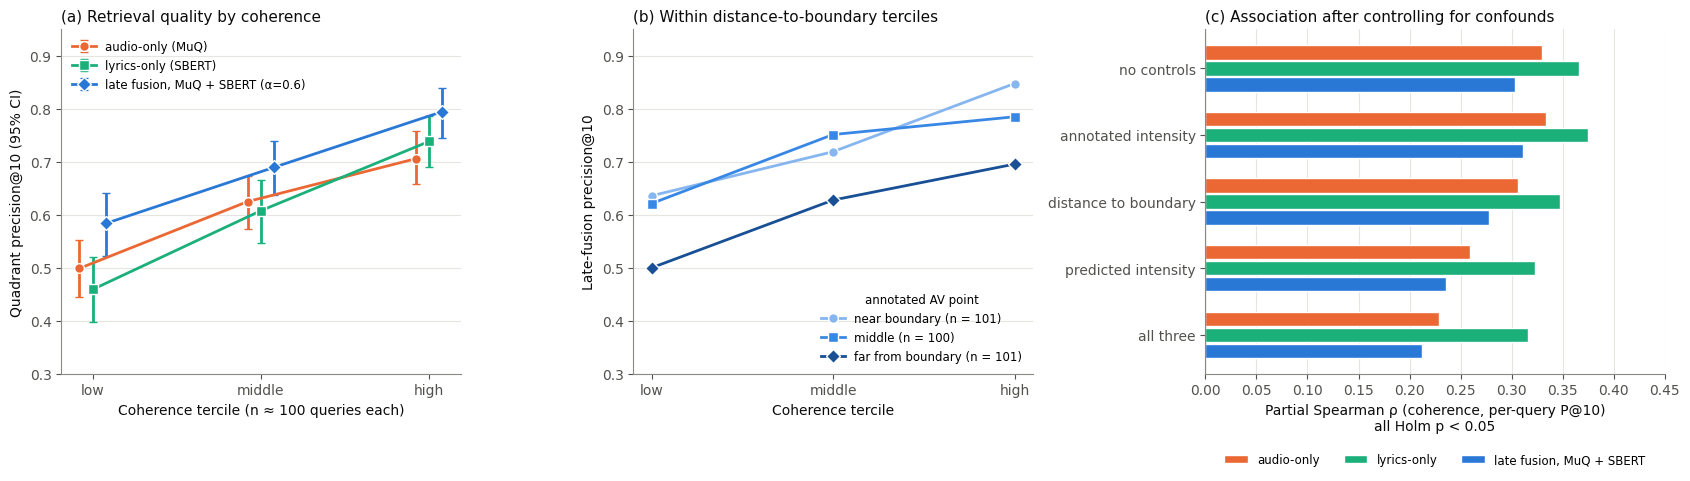

Saved: *_artist.csv and *_artist.png


In [7]:
coh = pd.read_parquet(os.path.join(OUT_DIR, 'coherence_muq_af.parquet')).set_index('song_id')
res = RES['70/15/15']; late = [k for k in res if k.startswith('late fusion (')][0]
qids = res['audio-only (MuQ)']['song_id']
cq = coh.loc[qids]
terc = pd.qcut(cq.coh_cos.values, 3, labels=['low', 'mid', 'high'])
bnd = np.minimum(np.abs(cq.arousal - 0.5), np.abs(cq.valence - 0.5)).values
bterc = pd.qcut(bnd, 3, labels=['near boundary', 'middle', 'far from boundary'])
conf = pd.read_csv(os.path.join(OUT_DIR, 'coherence_confound_check_muq_artist_af.csv'))

fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={'width_ratios': [1, 1, 1.15]})
# (a) P@10 by coherence tercile for each strategy
ax = axes[0]; xs = np.arange(3)
for k, name in enumerate(['audio-only (MuQ)', 'lyrics-only (SBERT)', late]):
    st = style(name); v = res[name]['P@K'][:, 9]
    means, lo, hi = [], [], []
    for t_ in ['low', 'mid', 'high']:
        x = v[np.asarray(terc == t_)]; c = boot_ci(x, 2000); means.append(x.mean()); lo.append(x.mean() - c[0]); hi.append(c[1] - x.mean())
    off = (k - 1) * 0.08
    ax.errorbar(xs + off, means, yerr=[lo, hi], color=st['color'], marker=st['marker'], ms=7, mec='white', lw=2, capsize=3,
                label=st['label'])
ax.set_xticks(xs); ax.set_xticklabels(['low', 'middle', 'high']); ax.set_xlabel('Coherence tercile (n ≈ 100 queries each)')
ax.set_ylabel('Quadrant precision@10 (95% CI)'); ax.set_ylim(0.3, 0.95)
ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title('(a) Retrieval quality by coherence', loc='left')
ax.legend(fontsize=8.5, loc='upper left')
# (b) fused P@10 by coherence tercile within boundary-distance terciles (sequential blue: near → far)
ax = axes[1]; v = res[late]['P@K'][:, 9]
for b_, col, mk in zip(['near boundary', 'middle', 'far from boundary'], ['#86b6ef', '#3987e5', '#184f95'], ['o', 's', 'D']):
    sel = np.asarray(bterc == b_)
    means = [v[sel & np.asarray(terc == t_)].mean() for t_ in ['low', 'mid', 'high']]
    ns = [int((sel & np.asarray(terc == t_)).sum()) for t_ in ['low', 'mid', 'high']]
    ax.plot(xs, means, color=col, marker=mk, ms=7, mec='white', lw=2, label=f'{b_} (n = {sum(ns)})')
ax.set_xticks(xs); ax.set_xticklabels(['low', 'middle', 'high']); ax.set_xlabel('Coherence tercile')
ax.set_ylabel('Late-fusion precision@10'); ax.set_ylim(0.3, 0.95)
ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title('(b) Within distance-to-boundary terciles', loc='left')
ax.legend(fontsize=8.5, loc='lower right', title='annotated AV point', title_fontsize=8.5)
# (c) partial Spearman under each control set
ax = axes[2]
ctrl = ['none', 'label intensity', 'boundary distance', 'predicted intensity', 'all three']
outs = [('P10_audio_only', 'audio-only (MuQ)'), ('P10_lyrics_only', 'lyrics-only (SBERT)'), ('P10_late_0.6', late)]
y0 = np.arange(len(ctrl))[::-1]; h = 0.24
for k, (col, name) in enumerate(outs):
    st = style(name); g = conf[conf.outcome == col].set_index('controls').loc[ctrl]
    ax.barh(y0 + (1 - k) * h, g.partial_spearman, h * 0.9, color=st['color'], edgecolor='white', label=st['label'].split(' (')[0])
ax.axvline(0, color=INK2, lw=0.8)
ax.set_yticks(y0); ax.set_yticklabels(['no controls', 'annotated intensity', 'distance to boundary', 'predicted intensity', 'all three'])
ax.set_xlabel('Partial Spearman ρ (coherence, per-query P@10)\nall Holm p < 0.05'); ax.set_xlim(0, 0.45)
ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title('(c) Association after controlling for confounds', loc='left')
ax.legend(fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'coherence_vs_retrieval_artist_af.png'), dpi=200, bbox_inches='tight'); plt.show()
print('Saved: *_artist.csv and *_artist.png')